loading libraries

In [89]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

read csv

In [90]:
df = pd.read_parquet("../data/combined_all.parquet")

check csv

In [91]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1044848 entries, 0 to 1044847
Data columns (total 16 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   invoice      1044848 non-null  string        
 1   stockcode    1044848 non-null  string        
 2   description  1040573 non-null  string        
 3   quantity     1044848 non-null  int64         
 4   invoicedate  1044848 non-null  datetime64[us]
 5   price        1044848 non-null  float64       
 6   customerid   809561 non-null   float64       
 7   country      1044848 non-null  str           
 8   year         1044848 non-null  int32         
 9   month        1044848 non-null  str           
 10  day          1044848 non-null  str           
 11  hour         1044848 non-null  int32         
 12  returned     1044848 non-null  str           
 13  gross_sales  1044848 non-null  float64       
 14  net_sales    1044848 non-null  float64       
 15  category     1044848 non-n

In [92]:
df.head()

,invoice,stockcode,description,quantity,invoicedate,price,customerid,country,year,month,day,hour,returned,gross_sales,net_sales,category
0,489434,85048,15cm christmas glass ball 20 lights,12,2009-12-01 07:45:00,6.95,13085.0,united kingdom,2009,December,Tuesday,7,no,83.4,83.4,christmas & seasonal decorations
1,489434,79323p,pink cherry lights,12,2009-12-01 07:45:00,6.75,13085.0,united kingdom,2009,December,Tuesday,7,no,81.0,81.0,"candles, lighting & fragrance"
2,489434,79323w,white cherry lights,12,2009-12-01 07:45:00,6.75,13085.0,united kingdom,2009,December,Tuesday,7,no,81.0,81.0,"candles, lighting & fragrance"
3,489434,22041,"record frame 7"" single size",48,2009-12-01 07:45:00,2.10,13085.0,united kingdom,2009,December,Tuesday,7,no,100.8,100.8,home decor & ornaments
4,489434,21232,strawberry ceramic trinket box,24,2009-12-01 07:45:00,1.25,13085.0,united kingdom,2009,December,Tuesday,7,no,30.0,30.0,storage & household organization


In [93]:
df["country"].value_counts()

country
united kingdom          959983
eire                     17689
germany                  17363
france                   14059
netherlands               5138
spain                     3766
switzerland               3183
belgium                   3111
portugal                  2540
australia                 1891
channel islands           1647
italy                     1509
sweden                    1364
norway                    1308
cyprus                    1176
finland                   1049
austria                    938
denmark                    797
unspecified                756
greece                     663
japan                      565
usa                        535
poland                     527
united arab emirates       500
israel                     371
hong kong                  364
singapore                  346
malta                      299
canada                     228
iceland                    222
rsa                        169
lithuania                  154


list

In [94]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]

revenue generated month to month

In [95]:
#revenue generated by the retail store
revenue = df["net_sales"].sum()
print(f"revenue generated by retail store is {revenue}")

revenue generated by retail store is 18909762.118


In [96]:
#revenue generated month to month
revenue_by_month = df.groupby(["year","month"]).agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index()
revenue_by_month["month"] = pd.Categorical(revenue_by_month["month"],categories=month_order,ordered=True)
revenue_by_month = revenue_by_month.sort_values(by=["year","month"])
revenue_by_month["aov"] = (revenue_by_month["net_revenue"] / revenue_by_month["orders"]).round(2)
revenue_by_month["revenue_growth_rate"] = (revenue_by_month["net_revenue"].pct_change() * 100).round(2)
revenue_by_month["volume_growth_rate"] = (revenue_by_month["volume"].pct_change() * 100).round(2)
revenue_by_month["orders_growth_rate"] = (revenue_by_month["orders"].pct_change() * 100).round(2)
revenue_by_month["aov_growth_rate"] = (revenue_by_month["aov"].pct_change() * 100).round(2)
revenue_by_month
revenue_by_month

,year,month,net_revenue,volume,orders,aov,revenue_growth_rate,volume_growth_rate,orders_growth_rate,aov_growth_rate
0,2009,December,799847.110,420088,2330,343.28,NaN,NaN,NaN,NaN
5,2010,January,624032.892,375363,1633,382.14,-21.98,-10.65,-29.91,11.32
4,2010,February,533091.426,368402,1969,270.74,-14.57,-1.85,20.58,-29.15
8,2010,March,765848.761,489370,2367,323.55,43.66,32.84,20.21,19.51
1,2010,April,590580.432,351971,1892,312.15,-22.89,-28.08,-20.07,-3.52
9,2010,May,615322.830,364095,2418,254.48,4.19,3.44,27.80,-18.48
7,2010,June,679786.610,388253,2216,306.76,10.48,6.64,-8.35,20.54
6,2010,July,575236.360,302201,2017,285.19,-15.38,-22.16,-8.98,-7.03
2,2010,August,656776.340,451803,1877,349.91,14.18,49.50,-6.94,22.69
12,2010,September,853650.431,478262,2375,359.43,29.98,5.86,26.53,2.72


revenue by year

In [97]:
revenue_year = df.groupby("year").agg(
    net_revenue = ("net_sales","sum"),
        volume = ("quantity","sum"),
        orders = ("invoice","nunique")
).reset_index().round(2)
revenue_year

,year,net_revenue,volume,orders
0,2009,799847.11,420088,2330
1,2010,9111106.09,5187533,27423
2,2011,8998808.91,4834223,23875


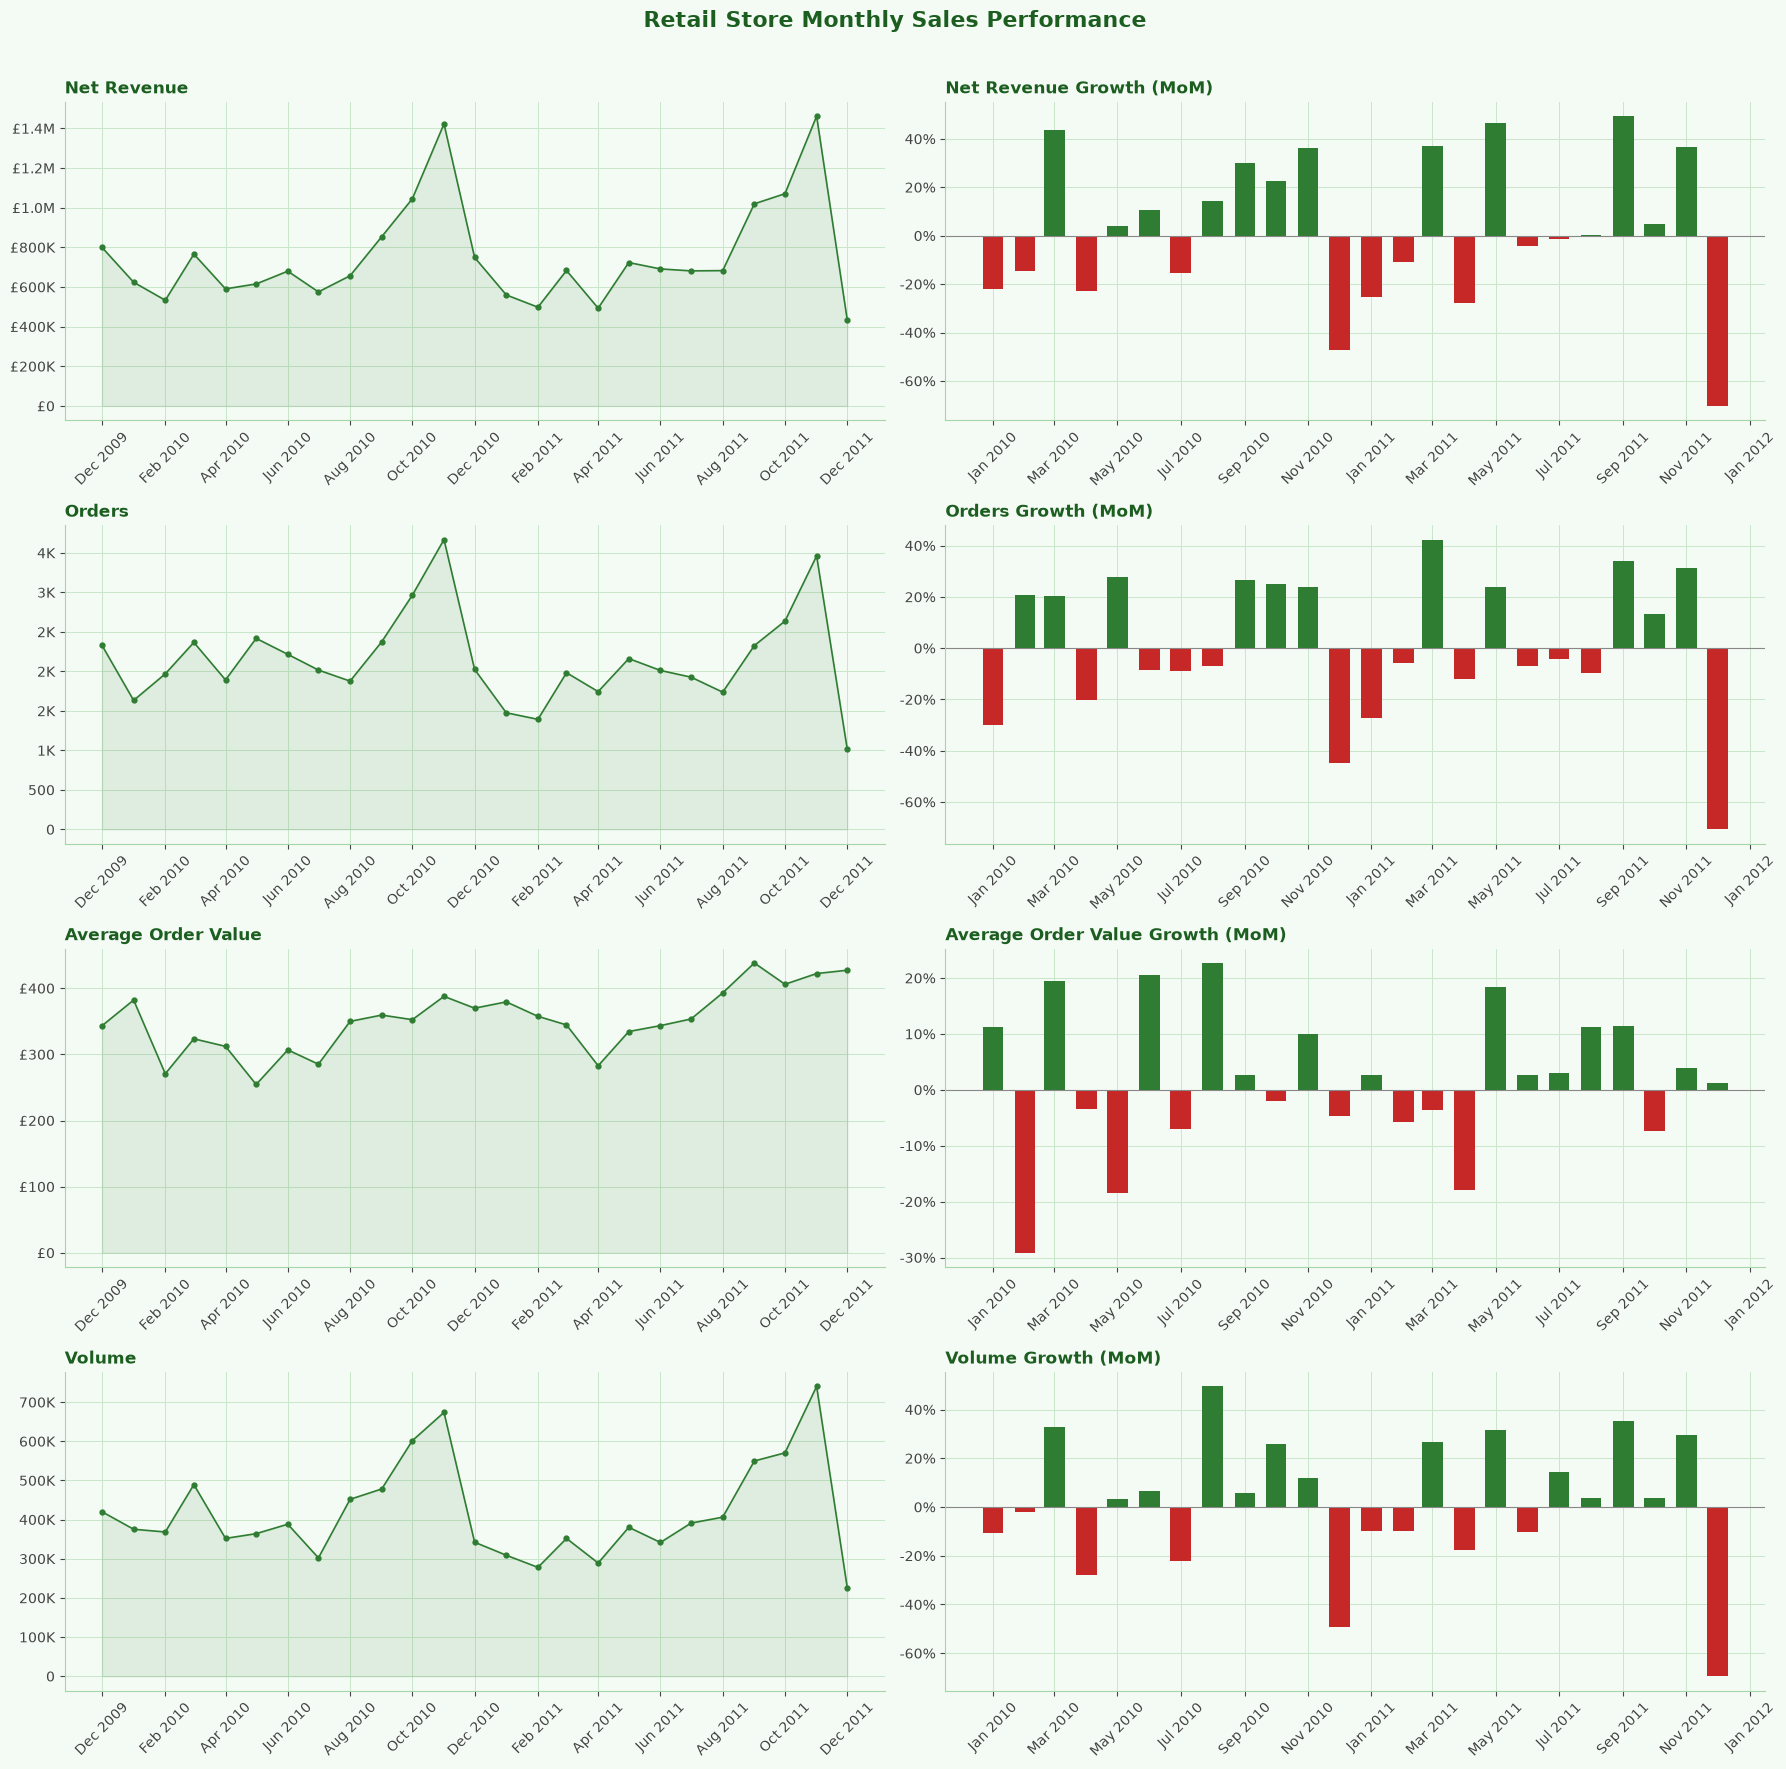

In [98]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

revenue_by_month = revenue_by_month.reset_index(drop=True)
revenue_by_month["period"] = pd.to_datetime(
    revenue_by_month["year"].astype(str) + "-" + revenue_by_month["month"].astype(str),
    format="%Y-%B"
)

dark, mid, neg, bg = "#1B5E20", "#2E7D32", "#C62828", "#F4FAF4"

def gbp(x, _):
    if abs(x) >= 1e6: return f"£{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"£{x/1e3:.0f}K"
    return f"£{x:,.0f}"

def num(x, _):
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.0f}K"
    return f"{x:,.0f}"

pct = lambda x, _: f"{x:.0f}%"

metrics = [
    ("net_revenue", "revenue_growth_rate", "Net Revenue", gbp),
    ("orders", "orders_growth_rate", "Orders", num),
    ("aov", "aov_growth_rate", "Average Order Value", gbp),
    ("volume", "volume_growth_rate", "Volume", num),
]

fig, axes = plt.subplots(4, 2, figsize=(18, 18), facecolor=bg)

for row, (col, gcol, title, fmt) in zip(axes, metrics):
    ax, bx = row

    # metric (line)
    ax.plot(revenue_by_month["period"], revenue_by_month[col],
            color=mid, linewidth=1.2, marker="o", markersize=3.5)
    ax.fill_between(revenue_by_month["period"], revenue_by_month[col],
                    color=mid, alpha=0.10)
    ax.set_title(title, fontsize=12, fontweight="bold", color=dark, loc="left")
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))

    # growth rate (bar)
    colors = [mid if v >= 0 else neg for v in revenue_by_month[gcol].fillna(0)]
    bx.bar(revenue_by_month["period"], revenue_by_month[gcol], width=20, color=colors)
    bx.axhline(0, color="#888", linewidth=0.8)
    bx.set_title(f"{title} Growth (MoM)", fontsize=12, fontweight="bold",
                 color=dark, loc="left")
    bx.yaxis.set_major_formatter(FuncFormatter(pct))

    for a in (ax, bx):
        a.set_facecolor(bg)
        a.grid(True, color="#C8E6C9", linewidth=0.7)
        a.set_axisbelow(True)
        for s in ["top", "right"]:
            a.spines[s].set_visible(False)
        for s in ["left", "bottom"]:
            a.spines[s].set_color("#A5D6A7")
        a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        a.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        a.tick_params(axis="x", rotation=45, colors="#444")
        a.tick_params(axis="y", colors="#444")

fig.suptitle("Retail Store Monthly Sales Performance", fontsize=16,
             fontweight="bold", color=dark)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

investigate monthly trend 

In [99]:
df["country"].nunique()

43

In [100]:
#revenue generated month to month
country_inv = df.groupby(["country","year","month"]).agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index()
country_inv["month"] = pd.Categorical(country_inv["month"],categories=month_order,ordered=True)
country_inv = country_inv.sort_values(by=["year","month"])
# country_inv["aov"] = (country_inv["net_revenue"] / country_inv["orders"]).round(2)
# country_inv["revenue_growth_rate"] = (country_inv["net_revenue"].pct_change() * 100).round(2)
# country_inv["volume_growth_rate"] = (country_inv["volume"].pct_change() * 100).round(2)
# country_inv["orders_growth_rate"] = (country_inv["orders"].pct_change() * 100).round(2)
# country_inv["aov_growth_rate"] = (country_inv["aov"].pct_change() * 100).round(2)
# country_inv
country_inv

,country,year,month,net_revenue,volume,orders
0,australia,2009,December,50.25,53,5
23,austria,2009,December,1998.34,564,2
52,belgium,2009,December,447.60,153,3
87,channel islands,2009,December,945.38,432,2
110,cyprus,2009,December,3425.08,1336,6
...,...,...,...,...,...,...
438,portugal,2011,December,2801.95,1566,5
475,spain,2011,December,271.43,256,3
500,sweden,2011,December,0.00,0,2
560,united kingdom,2011,December,388735.43,199907,922


In [101]:
country_inv_pivot = pd.pivot_table(country_inv,index=["country","year"],columns=["month"],values="net_revenue",fill_value=0).reset_index()
country_inv_pivot.head(25)

month,country,year,January,February,March,April,May,June,July,August,September,October,November,December
0,australia,2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,50.25
1,australia,2010,0.00,1029.66,429.39,630.95,1312.70,3189.28,633.62,176.00,785.83,2989.15,18207.82,1005.10
2,australia,2011,9017.71,14627.47,17055.29,333.40,13628.51,25164.77,4767.57,22489.20,5031.73,17150.53,6805.99,0.00
3,austria,2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1998.34
4,austria,2010,0.00,1118.86,925.13,1388.54,582.04,268.10,0.00,1043.15,1589.12,1236.70,2873.30,257.04
5,austria,2011,0.00,518.36,1708.12,680.78,1249.43,-24.20,1191.95,1516.08,0.00,1043.78,1329.78,683.20
6,bahrain,2010,0.00,439.85,506.30,0.00,585.96,463.28,0.00,0.00,0.00,317.76,0.00,205.74
7,bahrain,2011,-205.74,0.00,0.00,0.00,548.40,0.00,0.00,0.00,0.00,0.00,0.00,0.00
8,belgium,2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,447.60
9,belgium,2010,1624.07,1700.35,904.02,2549.14,84.95,3535.39,1914.23,1713.62,1190.06,1475.72,5178.28,1809.91


In [102]:
country_inv_pivot[country_inv_pivot["country"] == "united kingdom"]

month,country,year,January,February,March,April,May,June,July,August,September,October,November,December
92,united kingdom,2009,0.000,0.000,0.000,0.000,0.00,0.00,0.000,0.00,0.000,0.00,0.000,727655.96
93,united kingdom,2010,491108.702,444249.836,676956.671,497154.191,520678.69,581661.63,489766.170,561260.65,726528.311,894566.85,1239207.632,676742.62
94,united kingdom,2011,434308.300,408247.910,559707.390,442254.041,596459.86,554478.35,565479.841,539130.50,862018.152,877438.19,1282805.780,388735.43


how many percent of revenue is generated from each country

In [103]:
country_analysis = df.groupby("country").agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index().sort_values(by="net_revenue",ascending=False)
country_analysis["item_per_order"] = (country_analysis["volume"]/country_analysis["orders"]).round(2)
country_analysis["revenue_pct"] = (country_analysis["net_revenue"]/country_analysis["net_revenue"].sum() * 100).round(2)
country_analysis

,country,net_revenue,volume,orders,item_per_order,revenue_pct
39,united kingdom,1.603860e+07,8544941,49108,174.00,84.82
11,eire,6.102443e+05,327618,806,406.47,3.23
26,netherlands,5.483323e+05,381854,250,1527.42,2.90
15,germany,4.125178e+05,222030,1095,202.77,2.18
14,france,3.219285e+05,181768,746,243.66,1.70
0,australia,1.665119e+05,103385,117,883.63,0.88
36,switzerland,9.942536e+04,52268,123,424.94,0.53
34,spain,9.106476e+04,44689,188,237.71,0.48
35,sweden,8.780942e+04,87875,129,681.20,0.46
10,denmark,6.445959e+04,234764,53,4429.51,0.34


investigating category

In [104]:
category_summary = df.groupby("category").agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index().sort_values(by="net_revenue",ascending=False)
category_summary["item_per_order"] = (category_summary["volume"]/category_summary["orders"]).round(2)
category_summary["revenue_pct"] = (category_summary["net_revenue"]/category_summary["net_revenue"].sum() * 100).round(2)
category_summary

,category,net_revenue,volume,orders,item_per_order,revenue_pct
7,home decor & ornaments,2708197.380,1386333,27411,50.58,14.32
9,kitchenware & dining,2542298.700,1171941,27504,42.61,13.44
0,bags & travel accessories,2198988.920,1206380,20215,59.68,11.63
15,textiles & soft furnishings,1812764.237,472801,19066,24.80,9.59
14,storage & household organization,1808622.630,685774,24834,27.61,9.56
2,"candles, lighting & fragrance",1742598.700,1025607,23373,43.88,9.22
12,party & gift supplies,1734860.750,1881797,22680,82.97,9.17
11,other,1202923.111,466484,24096,19.36,6.36
3,christmas & seasonal decorations,1051436.590,698999,12962,53.93,5.56
17,toys & games,567023.950,438007,13326,32.87,3.00


In [105]:
category_indepth = df.groupby(["category","year","month"]).agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index()

category_indepth["month"] = pd.Categorical(category_indepth["month"], categories=month_order, ordered=True)
category_indepth = category_indepth.sort_values(by=["category","year","month"]).reset_index(drop=True)

category_indepth["aov"] = (category_indepth["net_revenue"] / category_indepth["orders"]).round(2)

# growth rates calculated within each category
g = category_indepth.groupby("category")
category_indepth["revenue_growth_rate"] = (g["net_revenue"].pct_change() * 100).round(2)
category_indepth["volume_growth_rate"] = (g["volume"].pct_change() * 100).round(2)
category_indepth["orders_growth_rate"] = (g["orders"].pct_change() * 100).round(2)
category_indepth["aov_growth_rate"] = (g["aov"].pct_change() * 100).round(2)

category_indepth

,category,year,month,net_revenue,volume,orders,aov,revenue_growth_rate,volume_growth_rate,orders_growth_rate,aov_growth_rate
0,bags & travel accessories,2009,December,98264.27,48434,844,116.43,NaN,NaN,NaN,NaN
1,bags & travel accessories,2010,January,76527.65,40098,532,143.85,-22.12,-17.21,-36.97,23.55
2,bags & travel accessories,2010,February,62745.64,47151,658,95.36,-18.01,17.59,23.68,-33.71
3,bags & travel accessories,2010,March,79032.88,43731,914,86.47,25.96,-7.25,38.91,-9.32
4,bags & travel accessories,2010,April,79027.17,44847,809,97.69,-0.01,2.55,-11.49,12.98
...,...,...,...,...,...,...,...,...,...,...,...
470,unknown,2011,August,0.00,-2555,82,0.00,NaN,-44.24,-47.10,NaN
471,unknown,2011,September,0.00,-7149,99,0.00,NaN,179.80,20.73,NaN
472,unknown,2011,October,0.00,-365,104,0.00,NaN,-94.89,5.05,NaN
473,unknown,2011,November,0.00,907,75,0.00,NaN,-348.49,-27.88,NaN


In [106]:
category_inv_pivot = pd.pivot_table(category_indepth,index=["category","year"],columns=["month"],values="net_revenue",fill_value=0).reset_index()
category_inv_pivot.head(25)

month,category,year,January,February,March,April,May,June,July,August,September,October,November,December
0,bags & travel accessories,2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,98264.27
1,bags & travel accessories,2010,76527.65,62745.64,79032.88,79027.17,72681.45,102765.47,78925.56,92567.51,104943.10,85585.98,105259.72,55608.82
2,bags & travel accessories,2011,63243.54,51148.60,91751.85,54969.40,111731.44,103566.50,105661.35,132433.77,112609.06,101803.64,136436.59,39697.96
3,bathroom & personal care,2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7315.80
4,bathroom & personal care,2010,2978.08,3130.98,5409.09,5242.02,5411.51,4027.47,3638.74,3911.60,3748.73,4419.78,6268.20,3739.26
5,bathroom & personal care,2011,2804.49,1931.52,2149.82,1919.42,1941.13,1797.73,1449.40,1278.96,2228.59,2273.41,2603.01,644.36
6,"candles, lighting & fragrance",2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,121923.85
7,"candles, lighting & fragrance",2010,82873.04,50972.85,86404.79,63757.86,45604.68,58042.71,50580.80,53467.81,72044.43,95554.80,139746.60,77122.27
8,"candles, lighting & fragrance",2011,55301.91,37009.94,44510.12,35561.36,66070.60,48192.11,46426.28,49383.41,68618.22,89232.63,160156.84,44038.79
9,christmas & seasonal decorations,2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,36304.92


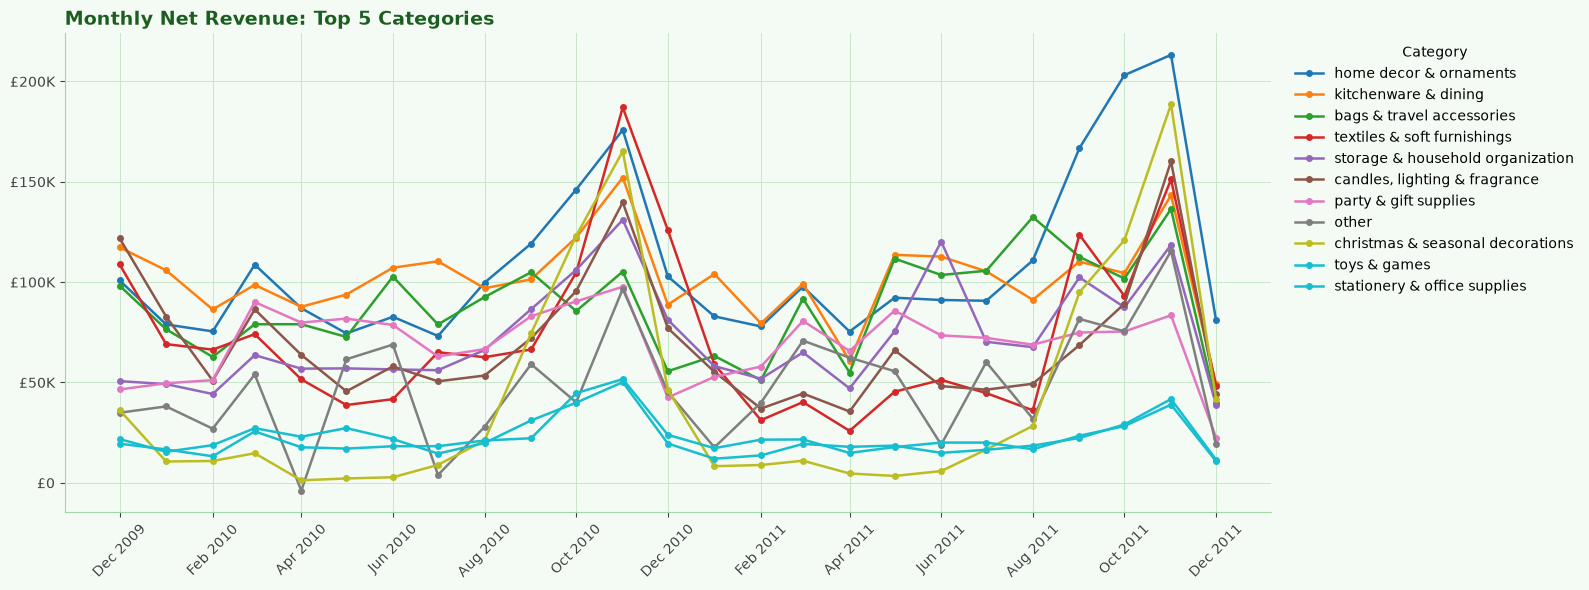

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

dark, mid, bg = "#1B5E20", "#2E7D32", "#F4FAF4"

def gbp(x, _):
    if abs(x) >= 1e6: return f"£{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"£{x/1e3:.0f}K"
    return f"£{x:,.0f}"

# top 5 categories by total net revenue across all years
top5 = (category_indepth.groupby("category")["net_revenue"]
        .sum().nlargest(11).index.tolist())

plot_df = category_indepth[category_indepth["category"].isin(top5)].copy()
plot_df["period"] = pd.to_datetime(
    plot_df["year"].astype(str) + "-" + plot_df["month"].astype(str),
    format="%Y-%B"
)

# one row per month, one column per category (missing months = 0)
wide = (plot_df.pivot_table(index="period", columns="category",
                            values="net_revenue", aggfunc="sum", fill_value=0)
        [top5])

colors = plt.cm.tab10(np.arange(len(top5)))

fig, ax = plt.subplots(figsize=(16, 6), facecolor=bg)

for cat, c in zip(top5, colors):
    ax.plot(wide.index, wide[cat], color=c, linewidth=1.8,
            marker="o", markersize=4, label=cat)

ax.set_title("Monthly Net Revenue: Top 5 Categories", fontsize=14,
             fontweight="bold", color=dark, loc="left")
ax.yaxis.set_major_formatter(FuncFormatter(gbp))
ax.set_facecolor(bg)
ax.grid(True, color="#C8E6C9", linewidth=0.7)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_color("#A5D6A7")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.tick_params(axis="x", rotation=45, colors="#444")
ax.tick_params(axis="y", colors="#444")

ax.legend(title="Category", frameon=False, loc="upper left",
          bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.show()